# Лабораторная работа №1 — ноутбук 2/3: Метрики

### Библиотеки и загрузка результатов ноутбука 1

Сначала выполните `1_eda.ipynb`. Если файлы `artifacts/train_clean.csv` и `artifacts/test_clean.csv` отсутствуют, вернитесь к первому ноутбуку и запустите его полностью.

In [3]:
import re
from collections import Counter, defaultdict
from functools import lru_cache
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
from IPython.display import display
from nltk.stem.snowball import RussianStemmer
from pymorphy3 import MorphAnalyzer

ARTIFACTS_DIR = Path("artifacts")
TRAIN_PATH = ARTIFACTS_DIR / "train_clean.csv"
TEST_PATH = ARTIFACTS_DIR / "test_clean.csv"

if not TRAIN_PATH.exists() or not TEST_PATH.exists():
    raise FileNotFoundError(
        "Не найдены artifacts/train_clean.csv и artifacts/test_clean.csv. "
        "Сначала выполните 1_eda.ipynb из той же рабочей папки."
    )

train_df = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
if "comment_clean" not in train_df.columns:
    raise ValueError("В train_clean.csv нет колонки comment_clean. Повторно выполните 1_eda.ipynb.")

train_seq = train_df["comment_clean"].fillna("").astype(str).map(str.split).tolist()
train_word_counts = Counter(
    token for sequence in train_seq
    for token in sequence
    if re.fullmatch(r"[а-яёa-z]+(?:[-'][а-яёa-z]+)*", token, flags=re.I)
)

print("Train:", train_df.shape, "| Test:", test_df.shape)
print("Слов в обучающем корпусе:", sum(train_word_counts.values()))
display(train_df[["comment", "comment_clean", "toxic"]].head(3))

Train: (11529, 3) | Test: (2883, 3)
Слов в обучающем корпусе: 315191


,comment,comment_clean,toxic
0,Вы читали закон о банкротстве? Что бы объявить...,<s> вы читали закон о банкротстве ? что бы объ...,0
1,а у сяоми это постоянно,<s> а у сяоми это постоянно </s>,0
2,"Хотел занять? Тогда да,проще позвонить , чем у...",<s> хотел занять ? тогда да проще позвонить че...,1


# 5. Стемминг и лемматизация


In [4]:
from pymorphy3 import MorphAnalyzer
stemmer = RussianStemmer()
morph = MorphAnalyzer()
SPECIALS = {"<s>", "</s>", "[URL]", "[USER]", "[NUM]", "[EMOJI]", "[UNK]", ".", "!", "?"}

def is_word(t):
    return t not in SPECIALS and bool(re.fullmatch(r"[а-яёa-z]+(?:[-'][а-яёa-z]+)*", t))

vocab_raw = sorted({t for seq in train_seq for t in seq if is_word(t)})

@lru_cache(maxsize=100_000)
def lemmatize(w):
    if not re.fullmatch(r"[а-яё-]+", w):
        return w
    return morph.parse(w)[0].normal_form

stems = {w: stemmer.stem(w) if re.fullmatch(r"[а-яё-]+", w) else w for w in vocab_raw}
lemmas = {w: lemmatize(w) for w in vocab_raw}

vocab_report = pd.DataFrame([
    {"вариант": "До нормализации", "уникальных токенов": len(vocab_raw)},
    {"вариант": "После стемминга", "уникальных токенов": len(set(stems.values()))},
    {"вариант": "После лемматизации", "уникальных токенов": len(set(lemmas.values()))},
])
vocab_report["доля от исходного, %"] = (100 * vocab_report["уникальных токенов"] / len(vocab_raw)).round(1)
display(vocab_report)

examples = [w for w in ("комментарии", "сообщениями", "плохого", "люди", "была", "прекрасный") if w in stems]
display(pd.DataFrame({"слово": examples, "основа": [stems[x] for x in examples],
                      "лемма": [lemmas[x] for x in examples]}))

,вариант,уникальных токенов,"доля от исходного, %"
0,До нормализации,59013,100.0
1,После стемминга,29503,50.0
2,После лемматизации,30780,52.2


,слово,основа,лемма
0,комментарии,комментар,комментарий
1,сообщениями,сообщен,сообщение
2,плохого,плох,плохой
3,люди,люд,человек
4,была,был,быть
5,прекрасный,прекрасн,прекрасный


In [5]:
raw_size = len(vocab_raw)
stem_size = len(set(stems.values()))
lemma_size = len(set(lemmas.values()))
print(f"Стемминг уменьшил Train-словарь на {raw_size-stem_size:,} типов "
      f"({100*(raw_size-stem_size)/raw_size:.1f}%).")
print(f"Лемматизация уменьшила Train-словарь на {raw_size-lemma_size:,} типов "
      f"({100*(raw_size-lemma_size)/raw_size:.1f}%).")
print("Более компактное представление:", "стемминг" if stem_size < lemma_size else
      "лемматизация" if lemma_size < stem_size else "размеры совпали")

Стемминг уменьшил Train-словарь на 29,510 типов (50.0%).
Лемматизация уменьшила Train-словарь на 28,233 типов (47.8%).
Более компактное представление: стемминг


,Исходное слово,Стемминг,Лемматизация
0,если,есл,если
1,только,тольк,только
2,есть,ест,есть
3,просто,прост,просто
4,было,был,быть
5,можно,можн,можно
6,даже,даж,даже
7,меня,мен,я
8,будет,будет,быть
9,может,может,мочь


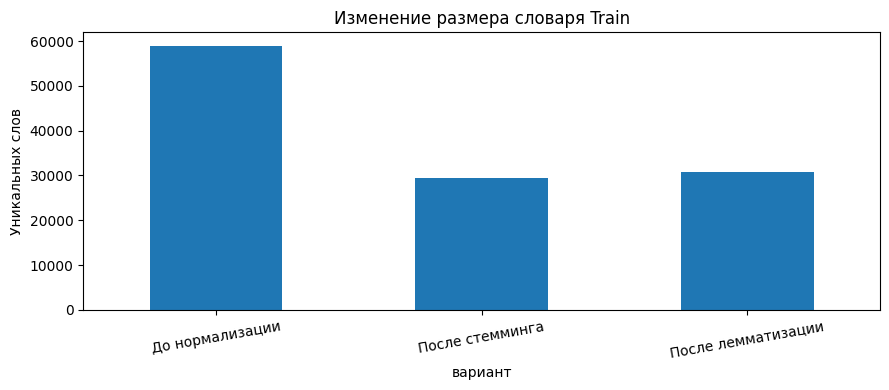

In [6]:
# Показываем преобразования на реально частотных словах корпуса.
examples_for_table = [w for w, _ in train_word_counts.most_common(400)
                      if w in stems and re.fullmatch(r'[а-яё]{4,}', w)][:25]
normalization_examples = pd.DataFrame({
    'Исходное слово': examples_for_table,
    'Стемминг': [stems[w] for w in examples_for_table],
    'Лемматизация': [lemmas[w] for w in examples_for_table],
})
display(normalization_examples.head(20))
ax = vocab_report.set_index('вариант')['уникальных токенов'].plot.bar(figsize=(9, 4), rot=10)
ax.set(title='Изменение размера словаря Train', ylabel='Уникальных слов')
plt.tight_layout(); plt.show()

# 6. Расстояние Левенштейна: поиск опечаток

Самостоятельно реализуем динамическое программирование с хранением только двух строк матрицы. Проверяем тестовые пары, а затем ищем варианты с расстоянием 1–2 среди слов обучающего корпуса.

In [7]:
def levenshtein(a: str, b: str, max_dist=None) -> int:
    """Расстояние редактирования: вставки/удаления/замены, две строки DP.
    При max_dist допускается раннее завершение, если превышена граница.
    """
    if len(a) < len(b):
        a, b = b, a
    if not b:
        return len(a)
    if max_dist is not None and len(a) - len(b) > max_dist:
        return max_dist + 1
    prev = list(range(len(b) + 1))
    for i, ca in enumerate(a, 1):
        cur = [i] + [0] * len(b)
        for j, cb in enumerate(b, 1):
            cur[j] = min(prev[j] + 1, cur[j - 1] + 1, prev[j - 1] + (ca != cb))
        if max_dist is not None and min(cur) > max_dist:
            return max_dist + 1
        prev = cur
    return prev[-1]

assert levenshtein("кот", "кит") == 1
assert levenshtein("комментарий", "коментарий") == 1
assert levenshtein("абв", "xyz") == 3
assert levenshtein("", "тест") == 4
print("Юнит-тесты расстояния Левенштейна пройдены.")

Юнит-тесты расстояния Левенштейна пройдены.


In [8]:
for first, second in [('кот','кит'), ('комментарий','коментарий'), ('привет','привед')]:
    print(f'd({first!r}, {second!r}) = {levenshtein(first, second)}')

d('кот', 'кит') = 1
d('комментарий', 'коментарий') = 1
d('привет', 'привед') = 1


In [ ]:
def deletion_signatures(w, depth=2):
    seen = {w}
    layer = {w}
    for _ in range(depth):
        layer = {x[:i] + x[i+1:] for x in layer for i in range(len(x))}
        seen.update(layer)
    return seen

word_freq = Counter(t for seq in train_seq for t in seq if is_word(t))
search_words = [w for w, f in word_freq.most_common() if re.fullmatch(r"[а-яё]{5,14}", w)][:3500]
index = defaultdict(list)
candidate_pairs = set()
for word in search_words:
    for signature in deletion_signatures(word, depth=2):
        for other in index[signature]:
            if abs(len(word)-len(other)) <= 2:
                candidate_pairs.add(tuple(sorted([word, other])))
        index[signature].append(word)

pairs = []
for a, b in candidate_pairs:
    d = levenshtein(a, b, max_dist=2)
    if d in (1, 2):
        frequent, rare = sorted([a, b], key=lambda x: word_freq[x], reverse=True)
        ratio = word_freq[frequent] / max(word_freq[rare], 1)
        pairs.append({"возможный оригинал": frequent, "вариант": rare, "d": d,
                      "freq_ориг": word_freq[frequent], "freq_вариант": word_freq[rare],
                      "отношение частот": ratio})
# Приоритет асимметричных пар: возможно опечатка редкого слова вместо частого.
pairs_df = pd.DataFrame(pairs)
if len(pairs_df):
    pairs_df = pairs_df.sort_values(["отношение частот", "freq_ориг"], ascending=False)
    display(pairs_df.head(10).reset_index(drop=True))
else:
    pairs_df = pd.DataFrame(columns=["возможный оригинал", "вариант", "d", "freq_ориг", "freq_вариант", "отношение частот"])
    print("Пары на выбранном частотном подсловаре не обнаружены.")
print("Исследовано слов:", len(search_words), "Кандидатных пар:", len(candidate_pairs))

,возможный оригинал,вариант,d,freq_ориг,freq_вариант,отношение частот
0,только,молоко,2,1110,7,158.571429
1,только,толком,2,1110,10,111.000000
2,просто,прост,1,870,8,108.750000
3,просто,просит,2,870,9,96.666667
4,просто,простая,2,870,10,87.000000
5,просто,просят,2,870,10,87.000000
6,просто,просил,2,870,10,87.000000
7,только,толку,2,1110,13,85.384615
8,может,сможете,2,657,8,82.125000
9,просто,простых,2,870,11,79.090909


Исследовано слов: 3500 Кандидатных пар: 13967


In [ ]:
if len(pairs_df):
    for _, pair in pairs_df.head(5).iterrows():
        a, b = pair['возможный оригинал'], pair['вариант']
        print(f'{a} ↔ {b}: расстояние={pair["d"]}, частоты {pair["freq_ориг"]}/{pair["freq_вариант"]}')
        matches = train_df.loc[train_df['comment'].str.contains(r'(?i)\b' + re.escape(b) + r'\b', regex=True), 'comment']
        if len(matches):
            print('  Контекст:', matches.iloc[0][:170].replace('\n', ' '))

только ↔ молоко: расстояние=2, частоты 1110/7
  Контекст: Вот это оперативность.. в ситуации со списанием разобрались - программная ошибка. Но тем не менее, пожалуй, останусь при своём мнении. Согласитесь - безлимитный интернет 
только ↔ толком: расстояние=2, частоты 1110/10
  Контекст: Эм.. а чем он отличается? Забивать лежачего чувака ногами, который к тебе впервые докопался и о котором ты толком ничего не знаешь может стоит быть всё таки адекватными, 
просто ↔ прост: расстояние=1, частоты 870/8
  Контекст: Ну двое первых друг у друга слизали, или, посовещавшись, написали один ответ на двоих. Вспомнился случай. У нас в универе был краткий курс по бизнес-планированию, и самая
просто ↔ просит: расстояние=2, частоты 870/9
  Контекст: Забальзамированные тела северокорейских лидеров Ким Ир Сена и Ким Чен Ира необходимо использовать в качестве рычага давления на нынешние власти КНДР. С такой инициативой 
просто ↔ простая: расстояние=2, частоты 870/10
  Контекст: Да. Закон не устанавливает 

**Ограничение:** расстояние 1–2 не доказывает опечатку; это могут быть словоформы или самостоятельные слова. Топ-10 выше — **кандидаты**, интерпретировать их нужно с учётом контекста. Индексация первых 3500 частотных слов ограничивает покрытие, но избавляет от полного перебора квадратного числа пар.

## Сохранение сводки метрик

Эта таблица используется в заключительном ноутбуке `3_modeling.ipynb`, чтобы собрать основные результаты трёх частей работы.

In [11]:
metrics_summary = pd.DataFrame([
    ("Уникальных слов до нормализации", raw_size),
    ("Уникальных слов после стемминга", stem_size),
    ("Уникальных слов после лемматизации", lemma_size),
    ("Кандидатных пар Левенштейна (d=1 или 2)", len(pairs_df)),
], columns=["Показатель", "Значение"])
ARTIFACTS_DIR.mkdir(exist_ok=True)
metrics_summary.to_csv(ARTIFACTS_DIR / "metrics_summary.csv", index=False, encoding="utf-8")
display(metrics_summary)
print("Сводка сохранена:", (ARTIFACTS_DIR / "metrics_summary.csv").resolve())

,Показатель,Значение
0,Уникальных слов до нормализации,59013
1,Уникальных слов после стемминга,29503
2,Уникальных слов после лемматизации,30780
3,Кандидатных пар Левенштейна (d=1 или 2),7439


Сводка сохранена: D:\ITMO\itmo_text_analysis_toxic_lab1_v4\lab1\artifacts\metrics_summary.csv
